In [58]:
import sys
print(sys.executable)

/usr/bin/python3


In [59]:
%pip install aiohttp

In [60]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [61]:
import os

os.makedirs(
    "images/Proyecto_integrador_graficas",
    exist_ok=True
)

In [62]:
%pip install atlasopenmagic uproot awkward vector numpy pandas matplotlib scipy scikit-learn requests

## How to rediscover the Higgs boson yourself!

<CENTER><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/images/ATLASOD.gif?raw=1" style="width:50%"></CENTER>

This notebook uses ATLAS Open Data http://opendata.atlas.cern 2025 beta release to show you the steps to rediscover the Higgs boson yourself!

ATLAS Open Data provides open access to proton-proton collision data at the LHC for educational purposes. ATLAS Open Data resources are ideal for high-school, undergraduate and postgraduate students.

Notebooks are web applications that allow you to create and share documents that can contain for example:
1. live code
2. visualisations
3. narrative text


### What is the Higgs boson?
The Higgs boson is a fundamental particle predicted by the Standard Model.
It is a manifestation of the Higgs field,
    which gives mass to the fundamental particles.
However,
    it is incredibly hard to produce.
At the LHC,
    a Higgs particle is produced about once every 10 billion collisions!
This tiny fraction makes it very difficult to detect.
Nevertheless,
    after years of data collection,
    the Higgs boson was finally discovered in 2012 by CMS and ATLAS experiments at CERN.
In this tutorial,
    we shall be following their example.


### Detecting the Higgs
This analysis loosely follows the paper on the [discovery of the Higgs boson by ATLAS](https://www.sciencedirect.com/science/article/pii/S037026931200857X) (mostly Section 4 and 4.1).

The Higgs boson can be produced in many different ways.
In particle physics,
    we describe these production modes using Feynman diagrams.
These diagrams allow us to visualise particle processes while also acting as powerful tools for calculations.
See [here](https://cds.cern.ch/record/2759490/files/Feynman%20Diagrams%20-%20ATLAS%20Cheat%20Sheet.pdf) for more information on Feynman diagrams.

There are four main production modes of the Higgs boson, and their respective Feynman diagrams:
1. Gluon-gluon fusion (top left)
2. Vector boson fusion (top right)
3. Vector boson bremsstrahlung (bottom left)
4. Top-antitop fusion (bottom right)

<table bgcolor="#FFFFFF">
    <tr  bgcolor="#FFFFFF">
        <td bgcolor=white><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/ggH.png?raw=1" style="width:70%"></td>
        <td bgcolor=white><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/VBFH.png?raw=1" style="width:75%"></td>
    </tr>
      <tr>
        <td><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/WH.png?raw=1" style="width:70%"> </td>
        <td><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/ttbarfusion.png?raw=1" style="width:75%"></td>
    </tr>
</table>

The Higgs has a very short lifetime, on the order of $10^{-22} \,\text{s}$. It decays extremely quickly after production, so there is no hope of directly detecting the particle. Nevertheless, we can use the Standard Model to predict its decay products: photons, Z bosons, quarks, etc., all with different probabilities. These **decay channels** can be used to identify the Higgs boson. In this notebook, we'll be looking at one particular decay channel: $$H \rightarrow ZZ^* \rightarrow \ell\ell\ell\ell$$

<CENTER><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/HZZ_feynman.png?raw=1" style="width:40%"></CENTER>


We refer to this as our desired **signal**.
Ideally,
    we would search for collisions which yield four leptons as products and this would tell us that a Higgs boson is present.
Unfortunately,
    in addition to our signal,
    there are many other **background** processes that lead to four reconstructed leptons in the final state.
The main background is $ZZ^*  \to \ell\ell\ell\ell$,
    where decay products have the same properties as those in the Higgs decay.
This is known as an irreducible background.
<CENTER><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/ZZ_leading.png?raw=1" style="width:40%"></CENTER>

We can get around this by accounting for the total invariant mass of the lepton products.
We know through conservation of energy and momentum that the invariant mass of the products must be equal to the Higgs mass, while other background processes will have different invariant masses.
Our last step would be to plot the invariant mass of each event and spot the peak in mass around $125\, \text{GeV}$, which corresponds to the mass of the Higgs boson.

We also have background contributions from $Z+$ jets and top-anti top processes, where additional charged leptons can arise either from semi-leptonic decays of heavy flavour or light flavour jets misidentified as leptons. We can also have contributions from processes with more than four leptons, but where one (or more) of the leptons are not reconstructed, and thus do not appear in our final selection. These backgrounds are difficult to remove completely.


<table bgcolor="#FFFFFF">
      <tr>
        <td bgcolor=white><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/Zllll.png?raw=1" style="width:70%"> </td>
          <td bgcolor=white><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/ttbar.png?raw=1" style="width:70%"> </td>
    </tr>
    <tr  bgcolor="#FFFFFF">
        <td bgcolor=white><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/ZZto4L.png?raw=1" style="width:70%"></td>
        <td bgcolor=white><img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/ImagesHiggs/WZto4L.png?raw=1" style="width:75%"></td>
    </tr>
</table>

For such processes,
    we will attempt to distinguish them from the Higgs decay using the properties of the leptons.
Because the Higgs is a neutral particle with zero lepton number,
    the lepton products from its decay must sum to zero charge and zero lepton numbers.
Thus,
    we can cut away all data with products that do not have these properties.
These cuts increase the ratio of our signal to the reducible background.

Note: $Z^*$/$W^*$ refer to a $Z$/$W$ boson that is off its mass shell.
This means that its mass is not fixed to the $91/80 \, \text{GeV}$ of a typical $Z$/$W$ boson.

By the end of this notebook you will be able to:
1. Learn to process large data sets using cuts
2. Understand some general principles of a particle physics analysis
3. Discover the Higgs boson!

See [here](https://cds.cern.ch/record/2800577/files/Signal%20and%20Background%20Physics%20Cheat%20Sheet.pdf) for more information on signals and backgrounds!

### Running a Python notebook
A Python notebook consists of cell blocks,
    each containing lines of Python code.
Each cell can be run independently of each other,
    yielding respective outputs below the cells.
Conventionally,
    cells are run in order from top to bottom.


- To run the whole notebook, in the top menu click Cell $\to$ Run All.

- To propagate a change you've made to a piece of code, click Cell $\to$ Run All Below.

- You can also run a single code cell, by clicking Cell $\to$ Run Cells, or using the keyboard shortcut Shift+Enter.

For more information,
    refer to [here](https://www.codecademy.com/article/how-to-use-jupyter-notebooks).

## ATLAS Open Data Initialisation

### First time package installation on your computer (not needed on mybinder)
This first cell installs the required python packages.
It only needs to be run the first time you open this notebook on your computer.
If you close Jupyter and re-open on the same computer, you won't need to run this first cell again.

If this is opened on mybinder, you don't need to run this cell.

In [63]:
import sys
import os.path
!pip install atlasopenmagic
from atlasopenmagic import install_from_environment
install_from_environment()

Installing packages: ['aiohttp>=3.9.5', 'atlasopenmagic>=1.9.0', 'awkward>=2.6.7', 'awkward-pandas>=2023.8.0', 'coffea~=0.7.0', 'fsspec>=2025.7.0', 'hist>=2.8.0', 'ipykernel>=6.29.5', 'jupyter>=1.0.0', 'lmfit>=1.3.2', 'matplotlib>=3.9.1', 'metakernel>=0.30.2', 'notebook<7', 'numpy>=1.26.4', 'pandas>=2.2.2', 'papermill>=2.6.0', 'pip>=24.2', 'scikit-learn>=1.5.1', 'uproot>=5.3.10', 'uproot3>=3.14.4', 'fsspec-xrootd>=0.5.1', 'jupyterlab_latex~=3.1.0', 'vector>=1.4.1']
Installation complete. You may need to restart your Python environment for changes to take effect.


We're going to import a number of packages to help us:
* `numpy`: provides numerical calculations such as histogramming
* `matplotlib`: common tool for making plots, figures, images, visualisations
* `uproot`: processes `.root` files typically used in particle physics into data formats used in python
* `awkward`: introduces `awkward` arrays, a format that generalizes `numpy` to nested data with possibly variable length lists
* `vector`: to allow vectorized 4-momentum calculations

In [64]:
import numpy as np # for numerical calculations such as histogramming
import matplotlib.pyplot as plt # for plotting
import matplotlib_inline # to edit the inline plot format
#matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg') # to make plots in pdf (vector) format
from matplotlib.ticker import AutoMinorLocator # for minor ticks
import uproot # for reading .root files
import awkward as ak # to represent nested data in columnar format
import vector # for 4-momentum calculations
import time # for printing time stamps
import requests # for file gathering, if needed

Unit definitions, as stored in the data files

In [65]:
MeV = 0.001
GeV = 1.0

We will use the [atlasopenmagic](https://opendata.atlas.cern/docs/data/atlasopenmagic) to access the open data directly from the ATLAS OpenData Portal so no need to download any samples. First we need to install the package

Import the module and load the release.

In [66]:
import atlasopenmagic as atom
atom.available_releases()
atom.set_release('2025e-13tev-beta')

Release '2025e-13tev-beta' already active with cached metadata.
Active release: 2025e-13tev-beta. (Datasets path: REMOTE)


Available releases:
2016e-8tev           2016 Open Data for education release of 8 TeV proton-proton collisions (https://opendata.cern.ch/record/3860).
2020e-13tev          2020 Open Data for education release of 13 TeV proton-proton collisions (https://cern.ch/2r7xt).
2024r-hi             2024 Open Data for research release for heavy-ion collisions (https://opendata.cern.ch/record/80035).
2024r-pp             2024 Open Data for research release for proton-proton collisions (https://opendata.cern.ch/record/80020).
2025e-13tev-beta     2025 Open Data for education and outreach beta release for 13 TeV proton-proton collisions (https://opendata.cern.ch/record/93910).
2025r-evgen-13p6tev  2025 Open Data for research release for event generation at 13.6 TeV (https://opendata.cern.ch/record/160000).
2025r-evgen-13tev    2025 Open Data for research release for event generation at 13 TeV (https://opendata.cern.ch/record/160000).
2026r-hihp           2026 Open Data for research release of heavy

## Example 1: Reading data

We would like to read some of the data from the open dataset.

In [67]:
lumi = 36.6 # fb-1 # data size of the full release
fraction = 1.0 # reduce this is if you want the code to run quicker

In [68]:
# Select the skim to use for the analysis
skim = "exactly4lep"

For convenient naming and identification purposes,
    we define a dictionary which stores all the important names of the samples we want to pull from the database.

In [69]:
defs = {
    r'Data':{'dids':['data']},
    r'Background $Z,t\bar{t},t\bar{t}+V,VVV$':{'dids': [410470,410155,410218,
                                                        410219,412043,364243,
                                                        364242,364246,364248,
                                                        700320,700321,700322,
                                                        700323,700324,700325], 'color': "#6b59d3" }, # purple
    r'Background $ZZ^{*}$':     {'dids': [700600],'color': "#ff0000" },# red
    r'Signal ($m_H$ = 125 GeV)':  {'dids': [345060, 346228, 346310, 346311, 346312,
                                          346340, 346341, 346342],'color': "#00cdff" },# light blue
}

samples   = atom.build_dataset(defs, skim=skim, protocol='https', cache=True)

The key named `data` refers to the event information collected from real experiments,
    while the `Background` and `Signal` keys refer to Monte-Carlo (MC) simulations of the ATLAS experiments.
Both real data and MC data will then be analysed and compared together to discover the Higgs!

Let's try accessing `data15_periodD` in the CERN database URL as an example.

In [70]:
# We shall use the first entry in 'list', 'data15_periodD'
data15_periodD = samples['Data']['list'][0]
print(f"{data15_periodD = }")

data15_periodD = 'simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_exactly4lep_data15_periodD.exactly4lep.root'


Next, we shall try opening the `data15_periodD` file to see what is inside.
In the file (called a `tree`),
    there are 39 entries,
    one for each event.
In each event,
    a dictionary stores the all relevant information as keys, such as the event number (`eventNumber`), lepton transverse momentum (`lep_pt`), etc.  
Details on the variables in the dictionary can be viewed [here](https://opendata.atlas.cern/docs/data/for_education/13TeV25_details#variable-list).

More information on trees can be viewed [here](https://masonproffitt.github.io/uproot-tutorial/03-trees/index.html).

In [71]:
# Accessing the file from the online database (":analysis" opens the tree in a desired manner)
tree = uproot.open(data15_periodD + ":analysis")

# There are 39 entries in the tree
print(tree.num_entries)

# We can view all the information stored in the tree using the .keys() method.
print(tree.keys())

# We can also view the entire tree using the .arrays() method
# This generates a 39-entry list of dictionaries
print(tree.arrays())

3424
['num_events', 'sum_of_weights', 'sum_of_weights_squared', 'category', 'TriggerMatch_DILEPTON', 'ScaleFactor_MLTRIGGER', 'ScaleFactor_PILEUP', 'ScaleFactor_FTAG', 'mcWeight', 'xsec', 'filteff', 'kfac', 'channelNumber', 'eventNumber', 'runNumber', 'trigML', 'trigP', 'trigDT', 'trigT', 'trigE', 'trigDM', 'trigDE', 'trigM', 'trigMET', 'ScaleFactor_BTAG', 'ScaleFactor_JVT', 'jet_n', 'jet_pt', 'jet_eta', 'jet_phi', 'jet_e', 'jet_btag_quantile', 'jet_jvt', 'largeRJet_n', 'largeRJet_pt', 'largeRJet_eta', 'largeRJet_phi', 'largeRJet_e', 'largeRJet_m', 'largeRJet_D2', 'jet_pt_jer1', 'jet_pt_jer2', 'ScaleFactor_ELE', 'ScaleFactor_MUON', 'ScaleFactor_LepTRIGGER', 'ScaleFactor_MuTRIGGER', 'ScaleFactor_ElTRIGGER', 'lep_n', 'lep_type', 'lep_pt', 'lep_eta', 'lep_phi', 'lep_e', 'lep_charge', 'lep_ptvarcone30', 'lep_topoetcone20', 'lep_z0', 'lep_d0', 'lep_d0sig', 'lep_isTightID', 'lep_isMediumID', 'lep_isLooseID', 'lep_isTightIso', 'lep_isLooseIso', 'lep_isTrigMatched', 'ScaleFactor_PHOTON', 'phot

Perhaps we'd like to see the lepton energies.
We can access this from our tree using the key `lep_e`.
Also,
    from this point on we shall be manipulating our tree arrays using the `awkward` library.
We can use `library="ak"` in the argument of the `.arrays()` method to use this library.
If you ever see `library="ak"` in the code,
    it means that the array is output as an `awkward` array.

In [72]:
tree["lep_e"].arrays(library="ak")

<Array [{lep_e: [91.3, ..., 23.5]}, ..., {...}] type='3424 * {lep_e: var * ...'>

In our analysis,
    not all the information in the tree is important.
We can store the important variables in a list and retrieve them from the tree later on.
As it turns out,
    we will need the following set of variables:

In [73]:
# Define what variables are important to our analysis
variables = ['lep_pt','lep_eta','lep_phi','lep_e','lep_charge','lep_type','trigE','trigM','lep_isTrigMatched',
            'lep_isLooseID','lep_isMediumID','lep_isLooseIso','lep_type']

# To see all the data for our given variables
# for data in tree.iterate(variables, library="ak"):
#     print(data)

Now that we understand how to access the information in the `data15_periodD` tree,
    we can begin analysis.
As mentioned in the introduction,
    there are two key steps to be completed for each event entry:
1. **Cuts** - we need to account for lepton selection rules in the event.
In the [paper](https://www.sciencedirect.com/science/article/pii/S037026931200857X),
    it is stated that we must
"[select] two pairs of isolated leptons, each of which is comprised of two leptons with the **same flavour** and **opposite charge**".
The datasets used in this notebook have already been filtered to include at least 4 leptons per event.
We need to filter the data such that in each event, there are pairs of leptons of the **same lepton type** (`lep_type`) and summing to **zero lepton charge** (`lep_charge`).

2. **Mass calculation** - the data to be plotted is the 4-lepton invariant mass, which can be found using the equation: $$m_\text{4l} = \sqrt{E^2_\text{tot}-\mathbf{p}_\text{tot}\cdot\mathbf{p}_\text{tot}}$$
in units where $c=1$.
$E_\text{tot}$ is the total energy and $\mathbf{p}_\text{tot}$ is the total momentum.
This calculation is performed using the vector array method `.M` on the sum of lepton 4-momenta (`lep_pt`,`lep_eta`,`lep_phi`,`lep_E`).

From this,
    we can see why we chose those six important variables earlier.
The physical reasoning for why we perform these steps is encapsulated in the idea of **conservation laws**.
You may read more [here](https://cds.cern.ch/record/2759491/files/Conservation%20Laws%20-%20ATLAS%20Physics%20Cheat%20Sheet.pdf).

Let's try to perform this two-step analysis for one event in `data15_periodD`.

Define function to get data from files.

The datasets used in this notebook have already been filtered to include at least 4 leptons per event, so that processing is quicker.

In [74]:
# This selects the first entry of the tree
entry = tree.arrays(library="ak")[:1]

# Cut lepton type (electron type is 11,  muon type is 13)
lep_type = entry['lep_type']
sum_lep_type = lep_type[:, 0] + lep_type[:, 1] + lep_type[:, 2] + lep_type[:, 3]
lep_type_cut_bool = (sum_lep_type != 44) & (sum_lep_type != 48) & (sum_lep_type != 52)
print(f"Cut for lepton type? {lep_type_cut_bool}") # True means we should remove this entry (lepton type does not match)

# Cut lepton charge
# first lepton in each event is [:, 0], 2nd lepton is [:, 1] etc
lep_charge = entry['lep_charge']
sum_lep_charge = lep_charge[:, 0] + lep_charge[:, 1] + lep_charge[:, 2] + lep_charge[:, 3] != 0
print(f"Cut for lepton charge? {sum_lep_charge}") # True means we should remove this entry (sum of lepton charges is not equal to 0)

# Calculate invariant mass of the 4-lepton state
# [:, i] selects the i-th lepton in each event
p4 = vector.zip({"pt": entry['lep_pt'], "eta": entry['lep_eta'], "phi": entry['lep_phi'], "E": entry['lep_e']})
invariant_mass = (p4[:, 0] + p4[:, 1] + p4[:, 2] + p4[:, 3]).M # .M calculates the invariant mass
print(f"Invariant mass: {invariant_mass}")

Cut for lepton type? [True]
Cut for lepton charge? [False]
Invariant mass: [5.6]


Based on our analysis, this entry should be removed because the lepton type does not match our requirements.
We can turn these checks and calculations into a set of functions.

In [75]:
# Cut lepton type (electron type is 11,  muon type is 13)
def cut_lep_type(lep_type):
    sum_lep_type = lep_type[:, 0] + lep_type[:, 1] + lep_type[:, 2] + lep_type[:, 3]
    lep_type_cut_bool = (sum_lep_type != 44) & (sum_lep_type != 48) & (sum_lep_type != 52)
    return lep_type_cut_bool # True means we should remove this entry (lepton type does not match)

# Cut lepton charge
def cut_lep_charge(lep_charge):
    # first lepton in each event is [:, 0], 2nd lepton is [:, 1] etc
    sum_lep_charge = lep_charge[:, 0] + lep_charge[:, 1] + lep_charge[:, 2] + lep_charge[:, 3] != 0
    return sum_lep_charge # True means we should remove this entry (sum of lepton charges is not equal to 0)

# Calculate invariant mass of the 4-lepton state
# [:, i] selects the i-th lepton in each event
def calc_mass(lep_pt, lep_eta, lep_phi, lep_e):
    p4 = vector.zip({"pt": lep_pt, "eta": lep_eta, "phi": lep_phi, "E": lep_e})
    invariant_mass = (p4[:, 0] + p4[:, 1] + p4[:, 2] + p4[:, 3]).M # .M calculates the invariant mass
    return invariant_mass


def cut_trig_match(lep_trigmatch):
    trigmatch = lep_trigmatch
    cut1 = ak.sum(trigmatch, axis=1) >= 1
    return cut1

def cut_trig(trigE,trigM):
    return trigE | trigM


def ID_iso_cut(IDel,IDmu,isoel,isomu,pid):
    thispid = pid
    return (ak.sum(((thispid == 13) & IDmu & isomu) | ((thispid == 11) & IDel & isoel), axis=1) == 4)

You may verify on your own that these functions give the same outputs as the previous code block.
Now,
    we shall apply these functions over the entire data tree using a `for` loop.

In [76]:
# Define empty list to hold all data for this sample
sample_data = []

# Perform the cuts for each data entry in the tree
for data in tree.iterate(variables, library="ak"): # the data will be in the form of an awkward array
    # We can use data[~boolean] to remove entries from the data set
    lep_type = data['lep_type']
    data = data[~cut_lep_type(lep_type)]
    lep_charge = data['lep_charge']
    data = data[~cut_lep_charge(lep_charge)]

    data['mass'] = calc_mass(data['lep_pt'], data['lep_eta'], data['lep_phi'], data['lep_e'])

    # Append data to the whole sample data list
    sample_data.append(data)

# turns sample_data back into an awkward array
data_A = ak.concatenate(sample_data)

We can now plot the data using Matplotlib.
The data will be turned into a histogram,
    with bins of width $2.5 \,\text{GeV}$.
Note that much of the code written here is meant for the aesthetics of the plot.

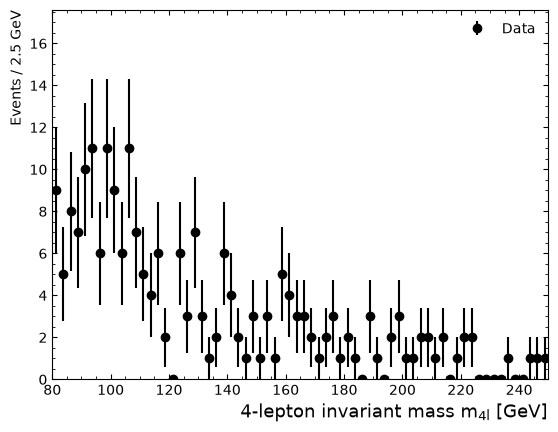

In [77]:
# x-axis range of the plot
xmin = 80 * GeV
xmax = 250 * GeV

# Histogram bin setup
step_size = 2.5 * GeV
bin_edges = np.arange(start=xmin, # The interval includes this value
                    stop=xmax+step_size, # The interval doesn't include this value
                    step=step_size ) # Spacing between values
bin_centres = np.arange(start=xmin+step_size/2, # The interval includes this value
                        stop=xmax+step_size/2, # The interval doesn't include this value
                        step=step_size ) # Spacing between values

# Creating histogram from data
data_x,_ = np.histogram(ak.to_numpy(data_A['mass']),
                        bins=bin_edges ) # histogram the data
data_x_errors = np.sqrt( data_x ) # statistical error on the data

# *************
# Main plot
# *************
main_axes = plt.gca() # get current axes

# plot the data points
main_axes.errorbar(x=bin_centres, y=data_x, yerr=data_x_errors,
                    fmt='ko', # 'k' means black and 'o' is for circles
                    label='Data')

# set the x-limit of the main axes
main_axes.set_xlim( left=xmin, right=xmax )

# separation of x axis minor ticks
main_axes.xaxis.set_minor_locator( AutoMinorLocator() )

# set the axis tick parameters for the main axes
main_axes.tick_params(which='both', # ticks on both x and y axes
                        direction='in', # Put ticks inside and outside the axes
                        top=True, # draw ticks on the top axis
                        right=True ) # draw ticks on right axis

# x-axis label
main_axes.set_xlabel(r'4-lepton invariant mass $\mathrm{m_{4l}}$ [GeV]',
                    fontsize=13, x=1, horizontalalignment='right' )

# write y-axis label for main axes
main_axes.set_ylabel('Events / '+str(step_size)+' GeV',
                        y=1, horizontalalignment='right')

# set y-axis limits for main axes
main_axes.set_ylim( bottom=0, top=np.amax(data_x)*1.6 )

# add minor ticks on y-axis for main axes
main_axes.yaxis.set_minor_locator( AutoMinorLocator() )

# draw the legend
main_axes.legend( frameon=False ); # no box around the legend

Great,
    we managed to plot `data15_periodD`!
Now,
    we have not discussed how to deal with the Monte-Carlo simulation data,
    or even what they are for.
Let us explain.

## Example 2: Reading Monte-Carlo data

Using the Standard Model, we can do a set of randomised simulations to produce a set of theoretical data points to compare to our ATLAS data. These are known as Monte-Carlo(MC) simulations. But there is one important change to be made to the MC data before we can compare them with our ATLAS data:

 - **Weights** - The MC data was simulated with *ideal* or *controlled* circumstances. However, the real ATLAS detector has some inefficiencies, which we can account for by attributing an appropriate weight to each data point. The weight of a data point affects how it contributes to the histogram count for its bin.

Let's open an MC file.

In [78]:
# We open an MC data file with simulated ttbar events (data set ID 410470)
value = samples[r'Background $Z,t\bar{t},t\bar{t}+V,VVV$']["list"][0]
print(value)

# This is now appended to our file path to retrieve the root file
background_ttbar_path = value

# Accessing the file from the online database
tree = uproot.open(background_ttbar_path + ":analysis")

simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_exactly4lep_mc_410470.PhPy8EG_A14_ttbar_hdamp258p75_nonallhad.exactly4lep.root


These are the weights which are important to our analysis:
- `scaleFactor_PILEUP` - scale factor for pileup reweighting
- `scaleFactor_ELE` - scale factor for electron efficiency
- `scaleFactor_MUON`- scale factor for muon efficiency
- `scaleFactor_LepTRIGGER` - scale factor for lepton triggers

Scale factors are generally related to estimates of the efficiencies and resolutions of detectors.

In [79]:
weight_variables = ["filteff","kfac","xsec","mcWeight","ScaleFactor_PILEUP", "ScaleFactor_ELE", "ScaleFactor_MUON", "ScaleFactor_LepTRIGGER"]

# For example, see below for the weights corresponding to muon rejection
tree["ScaleFactor_MUON"].arrays(library = "ak")
print(weight_variables)

['filteff', 'kfac', 'xsec', 'mcWeight', 'ScaleFactor_PILEUP', 'ScaleFactor_ELE', 'ScaleFactor_MUON', 'ScaleFactor_LepTRIGGER']


Additionally, there is a *cross section weight* $w_\sigma$ associated with each MC file. This weight is meant to normalise the entire Monte-Carlo distribution based on the number of events in the data. This is its definition:
$$ w_\sigma = \frac{\int L \text{d}t ~ \sigma \,\, \eta \,\, k \,\, w}{\sum_i w_i } $$
where
 * $\int L \text{d}t$ is the integrated luminosity in inverse femtobarns (`lumi`),
 * $\sigma$ is the cross section in picobarn (hence the factor $1000$ in the formula below) (`event["xsec"]`),
 * $\eta$ is the filter efficiency of the MC generator (`event["filteff"]`),
 * $k$ is the k-factor, a multiplicative correction factor used to account for higher-order effects in theoretical calculations of the cross section (`event["kfac"]`).
 * $w$ are weights added to a given simulated event by the event generator. These can be set to $1$ for many sampels and depends on the process being simulated and the generator used to simulate the events (`event["mcWeight"]`).
 * In datasets where events are assigned weights, the $\sum_i w_i$ value represents the cumulative total of these weights across all events in the dataset (`event["sum_of_weights"]`). If no weights are assigned to the events this (i.e. the weights are all set to 1) $\sum_i w_i$ simply gives the total number of simulated events. Note that the sum of weights is calculated before any selection has been applied and thus is typically much larger than what you get if you sum up the weights of the events in the ntuple.  

When the integrated luminosity is multiplied by the *cross section weight*, $w_\sigma$, of a certain process, it gives a measure of the total number of expected events during a period of data taking for the given process.

For `data_D`, the integrated luminosity has a value of $0.105 \,\text{fb}^{-1}$.

For more on cross sections and luminosities,
    [see this cheatsheet](https://cds.cern.ch/record/2800578/files/Cross%20Section%20and%20Luminosity%20Physics%20Cheat%20Sheet.pdf).

Now, with all the weights we've defined, we will calculate a total weight for an event in the $t\bar{t}$ sample scaled to the integrated luminosity of period D in data15. The total weight is the collective product of all the weights:

In [80]:
# luminosity of data_D
lumi = 0.105 #Luminosity of periodD in data 15 is 0.105 fb-1

# Let's use the first event of our tree
event = tree.arrays()[0]

# Multiply all the important weights together
total_weight = lumi * 1000 / event["sum_of_weights"]
for variable in weight_variables:
    total_weight = total_weight * event[variable]
print(f"{total_weight = }")

total_weight = np.float64(0.0017336209613845047)


This calculation means that in our final histogram,
    this event will be represented with $0.00173$ of a single count in the bin.
We can encapsulate these calculations in a single function `calc_weight`.

In [81]:
def calc_weight(weight_variables, events):
    total_weight = lumi * 1000 / events["sum_of_weights"]
    for variable in weight_variables:
        total_weight = total_weight * abs(events[variable])
    return total_weight

# Verify that we get the same answer
print(calc_weight(weight_variables, event))

0.0017336209613845047


Now, we can apply the cuts as before to plot the MC data.
The code is the same as before,
    but we make sure to add in `weight_variables` to our `tree.iterate()`,
    and we store the weights in each event using a new dictionary key.

In [82]:
sample_data = []

# Perform the cuts for each data entry in the tree
for data in tree.iterate(variables + weight_variables+['sum_of_weights'], library="ak"):
    # Cuts
    lep_type = data['lep_type']
    data = data[~cut_lep_type(lep_type)]
    lep_charge = data['lep_charge']
    data = data[~cut_lep_charge(lep_charge)]

    # Invariant Mass
    data['mass'] = calc_mass(data['lep_pt'], data['lep_eta'], data['lep_phi'], data['lep_e'])

    # Store Monte Carlo weights in the data
    data['totalWeight'] = calc_weight(weight_variables, data)
    # data['totalWeight'] = calc_weight(data)

    # Append data to the whole sample data list
    sample_data.append(data)

# turns sample_data back into an awkward array
background_ttbar = ak.concatenate(sample_data)

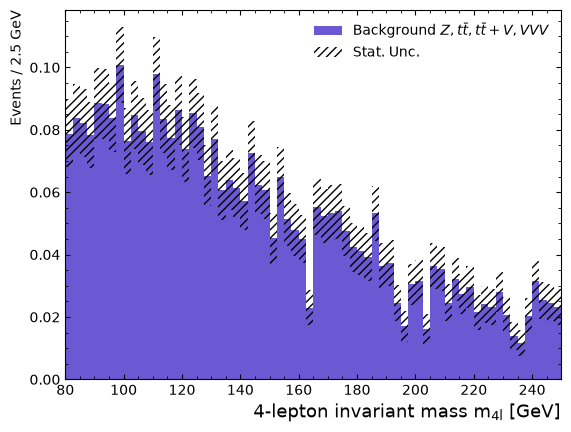

In [83]:
step_size = 2.5 * GeV

mc_x = ak.to_numpy(background_ttbar["mass"]) # define list to hold the Monte Carlo histogram entries
mc_weights = ak.to_numpy(background_ttbar["totalWeight"]) # define list to hold the Monte Carlo weights
mc_colors = samples[r'Background $Z,t\bar{t},t\bar{t}+V,VVV$']['color'] # define list to hold the colors of the Monte Carlo bars
mc_labels = r'Background $Z,t\bar{t},t\bar{t}+V,VVV$' # define list to hold the legend labels of the Monte Carlo bars

# *************
# Main plot
# *************
main_axes = plt.gca() # get current axes

# plot the data points
# main_axes.errorbar(x=bin_centres, y=data_x, yerr=data_x_errors,
#                     fmt='ko', # 'k' means black and 'o' is for circles
#                     label='Data')

# plot the Monte Carlo bars
mc_heights = main_axes.hist(mc_x, bins=bin_edges,
                            weights=mc_weights, stacked=True,
                            color=mc_colors, label=mc_labels )

mc_x_tot = mc_heights[0] # stacked background MC y-axis value

# calculate MC statistical uncertainty: sqrt(sum w^2)
mc_x_err = np.sqrt(np.histogram(np.hstack(mc_x), bins=bin_edges, weights=np.hstack(mc_weights)**2)[0])

# plot the statistical uncertainty
main_axes.bar(bin_centres, # x
                2*mc_x_err, # heights
                alpha=0.5, # half transparency
                bottom=mc_x_tot-mc_x_err, color='none',
                hatch="////", width=step_size, label='Stat. Unc.' )

# set the x-limit of the main axes
main_axes.set_xlim( left=xmin, right=xmax )

# separation of x axis minor ticks
main_axes.xaxis.set_minor_locator( AutoMinorLocator() )

# set the axis tick parameters for the main axes
main_axes.tick_params(which='both', # ticks on both x and y axes
                        direction='in', # Put ticks inside and outside the axes
                        top=True, # draw ticks on the top axis
                        right=True ) # draw ticks on right axis

# x-axis label
main_axes.set_xlabel(r'4-lepton invariant mass $\mathrm{m_{4l}}$ [GeV]',
                    fontsize=13, x=1, horizontalalignment='right' )

# write y-axis label for main axes
main_axes.set_ylabel('Events / '+str(step_size)+' GeV',
                        y=1, horizontalalignment='right')

# add minor ticks on y-axis for main axes
main_axes.yaxis.set_minor_locator( AutoMinorLocator() )

# draw the legend
main_axes.legend( frameon=False ); # no box around the legend

## Final Analysis

Now that we understand all the steps of our analysis,
    all that's left is to import the entire ATLAS data and implement it.
The `samples` dictionary will be useful for this.

We will loop over all values in the `samples` dictionary.
Depending on whether it is a data sample or MC sample,
    `fileString` will change,
    which opens the correct file on the open data folder.
As before,
    the cuts,
    mass calculations and MC weight calculations will be performed for each sample value,
    and then stored in the array.
The data will all be concatenated into `all_data` for plotting.

In [85]:
# Set luminosity to 36.6 fb-1, data size of the full release
lumi = 36.6

# Controls the fraction of all events analysed
fraction = 1.0 # reduce this is if you want quicker runtime (implemented in the loop over the tree)

# Define empty dictionary to hold awkward arrays
all_data = {}

# Loop over samples
for s in samples:

    # Print which sample is being processed
    print('Processing '+s+' samples')

    # Define empty list to hold data
    frames = []

    # Loop over each file
    for val in samples[s]['list']:
        if s == 'data':
            prefix = "Data/"
        else:
            prefix = "MC/mc_"
        fileString = val

        # start the clock
        start = time.time()
        print("\t"+val+":")

        # Open file with safety try-except block to handle remote download issues
        try:
            tree = uproot.open(fileString + ":analysis")
        except Exception as e:
            print(f"\t\t WARNING: Failed to open {val} due to: {e}. Skipping this file.")
            continue

        sample_data = []

        # Loop over data in the tree
        for data in tree.iterate(variables + weight_variables + ["sum_of_weights", "lep_n"],
                                 library="ak",
                                 entry_stop=tree.num_entries*fraction):

            # Number of events in this batch
            nIn = len(data)

            data = data[cut_trig(data.trigE, data.trigM)]
            data = data[cut_trig_match(data.lep_isTrigMatched)]

            # Record transverse momenta
            data['leading_lep_pt'] = data['lep_pt'][:,0]
            data['sub_leading_lep_pt'] = data['lep_pt'][:,1]
            data['third_leading_lep_pt'] = data['lep_pt'][:,2]
            data['last_lep_pt'] = data['lep_pt'][:,3]

            # Cuts on transverse momentum
            data = data[data['leading_lep_pt'] > 20]
            data = data[data['sub_leading_lep_pt'] > 15]
            data = data[data['third_leading_lep_pt'] > 10]

            data = data[ID_iso_cut(data.lep_isLooseID,
                                   data.lep_isMediumID,
                                   data.lep_isLooseIso,
                                   data.lep_isLooseIso,
                                   data.lep_type)]

            lep_type = data['lep_type']
            data = data[~cut_lep_type(lep_type)]
            lep_charge = data['lep_charge']
            data = data[~cut_lep_charge(lep_charge)]

            # Invariant Mass
            data['mass'] = calc_mass(data['lep_pt'], data['lep_eta'], data['lep_phi'], data['lep_e'])

            # Store Monte Carlo weights in the data
            if 'data' not in s:
                data['totalWeight'] = calc_weight(weight_variables, data)

            # Append data to the whole sample data list
            sample_data.append(data)

            if not 'data' in val:
                nOut = sum(data['totalWeight'])
            else:
                nOut = len(data)

            elapsed = time.time() - start
            print("\t\t nIn: "+str(nIn)+",\t nOut: \t"+str(nOut)+"\t in "+str(round(elapsed,1))+"s")

        if len(sample_data) > 0:
            frames.append(ak.concatenate(sample_data))

    if len(frames) > 0:
        all_data[s] = ak.concatenate(frames)

Processing Data samples
	simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_exactly4lep_data15_periodD.exactly4lep.root:
		 nIn: 3424,	 nOut: 	2	 in 1.6s
	simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_exactly4lep_data15_periodE.exactly4lep.root:
		 nIn: 25092,	 nOut: 	17	 in 2.0s
	simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_exactly4lep_data15_periodF.exactly4lep.root:
		 nIn: 16234,	 nOut: 	13	 in 0.9s
	simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_exactly4lep_data15_periodG.exactly4lep.root:
		 nIn: 37101,	 nOut: 	24	 in 1.5s
	simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_exactly4lep_data15_periodH.exactly4lep.root:
		 nIn: 12152,	 nOut: 	11	 in 1.0s
	simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_exactly4lep_data15_periodJ.exactly4lep.root:

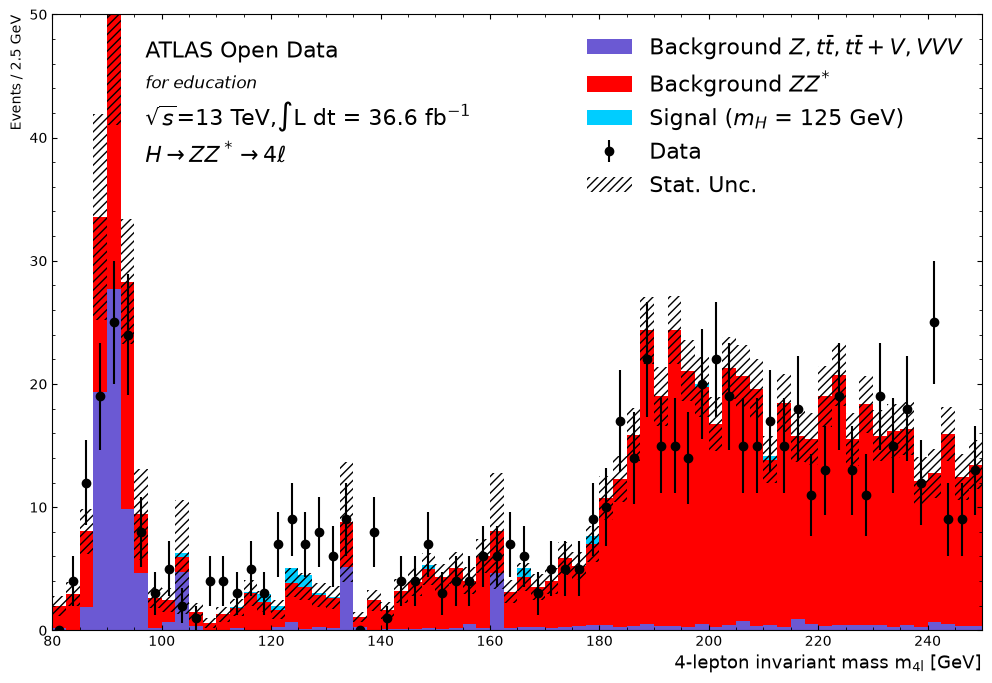

In [86]:
data_x,_ = np.histogram(ak.to_numpy(all_data['Data']['mass']),
                        bins=bin_edges ) # histogram the data
data_x_errors = np.sqrt( data_x ) # statistical error on the data

signal_x = ak.to_numpy(all_data[r'Signal ($m_H$ = 125 GeV)']['mass']) # histogram the signal
signal_weights = ak.to_numpy(all_data[r'Signal ($m_H$ = 125 GeV)'].totalWeight) # get the weights of the signal events
signal_color = samples[r'Signal ($m_H$ = 125 GeV)']['color'] # get the colour for the signal bar

mc_x = [] # define list to hold the Monte Carlo histogram entries
mc_weights = [] # define list to hold the Monte Carlo weights
mc_colors = [] # define list to hold the colors of the Monte Carlo bars
mc_labels = [] # define list to hold the legend labels of the Monte Carlo bars

for s in samples: # loop over samples
    if s not in ['Data', r'Signal ($m_H$ = 125 GeV)']: # if not data nor signal
        mc_x.append( ak.to_numpy(all_data[s]['mass']) ) # append to the list of Monte Carlo histogram entries
        mc_weights.append( ak.to_numpy(all_data[s].totalWeight) ) # append to the list of Monte Carlo weights
        mc_colors.append( samples[s]['color'] ) # append to the list of Monte Carlo bar colors
        mc_labels.append( s ) # append to the list of Monte Carlo legend labels

# *************
# Main plot
# *************
fig, main_axes = plt.subplots(figsize=(12, 8))

# plot the data points
main_axes.errorbar(x=bin_centres, y=data_x, yerr=data_x_errors,
                    fmt='ko', # 'k' means black and 'o' is for circles
                    label='Data')

# plot the Monte Carlo bars
mc_heights = main_axes.hist(mc_x, bins=bin_edges,
                            weights=mc_weights, stacked=True,
                            color=mc_colors, label=mc_labels )

mc_x_tot = mc_heights[0][-1] # stacked background MC y-axis value

# calculate MC statistical uncertainty: sqrt(sum w^2)
mc_x_err = np.sqrt(np.histogram(np.hstack(mc_x), bins=bin_edges, weights=np.hstack(mc_weights)**2)[0])

# plot the signal bar
signal_heights = main_axes.hist(signal_x, bins=bin_edges, bottom=mc_x_tot,
                weights=signal_weights, color=signal_color,
                label=r'Signal ($m_H$ = 125 GeV)')

# plot the statistical uncertainty
main_axes.bar(bin_centres, # x
                2*mc_x_err, # heights
                alpha=0.5, # half transparency
                bottom=mc_x_tot-mc_x_err, color='none',
                hatch="////", width=step_size, label='Stat. Unc.' )

# set the x-limit of the main axes
main_axes.set_xlim( left=xmin, right=xmax )

# separation of x axis minor ticks
main_axes.xaxis.set_minor_locator( AutoMinorLocator() )

# set the axis tick parameters for the main axes
main_axes.tick_params(which='both', # ticks on both x and y axes
                        direction='in', # Put ticks inside and outside the axes
                        top=True, # draw ticks on the top axis
                        right=True ) # draw ticks on right axis

# x-axis label
main_axes.set_xlabel(r'4-lepton invariant mass $\mathrm{m_{4l}}$ [GeV]',
                    fontsize=13, x=1, horizontalalignment='right' )

# write y-axis label for main axes
main_axes.set_ylabel('Events / '+str(step_size)+' GeV',
                        y=1, horizontalalignment='right')

# set y-axis limits for main axes
main_axes.set_ylim( bottom=0, top=np.amax(data_x)*2.0 )

# add minor ticks on y-axis for main axes
main_axes.yaxis.set_minor_locator( AutoMinorLocator() )

# Add text 'ATLAS Open Data' on plot
plt.text(0.1, # x
            0.93, # y
            'ATLAS Open Data', # text
            transform=main_axes.transAxes, # coordinate system used is that of main_axes
            fontsize=16 )

# Add text 'for education' on plot
plt.text(0.1, # x
            0.88, # y
            'for education', # text
            transform=main_axes.transAxes, # coordinate system used is that of main_axes
            style='italic',
            fontsize=12 )

# Add energy and luminosity
lumi_used = str(lumi*fraction) # luminosity to write on the plot
plt.text(0.1, # x
            0.82, # y
            r'$\sqrt{s}$=13 TeV,$\int$L dt = '+lumi_used+' fb$^{-1}$', # text
            transform=main_axes.transAxes,fontsize=16 ) # coordinate system used is that of main_axes

# Add a label for the analysis carried out
plt.text(0.1, # x
            0.76, # y
            r'$H \rightarrow ZZ^* \rightarrow 4\ell$', # text
            transform=main_axes.transAxes,fontsize=16 ) # coordinate system used is that of main_axes

# draw the legend
my_legend = main_axes.legend( frameon=False, fontsize=16 ) # no box around the legend

### Signal Significance

We can do some analysis to study how significant the signal is compared to the background.
One method is to check a quantity known as the signal significance $S$,
    which is defined by
$$ S = \frac{N_\text{sig}}{\sqrt{N_\text{bg}}}  $$
where $ N_\text{sig} $ and $N_\text{bg}$ are the number of signal and background points respectively.
A larger $S$ represents a better signal-to-background ratio,
    and a more significant signal peak.
To calculate $N_\text{sig}$,
    we can look at the plot and sum over the number of events of our Monte-Carlo signal.
The signal range roughly corresponds to the bins from $115 \,\text{GeV}$ to $130 \, \text{GeV}$.
$N_\text{bg}$ then corresponds to the number of background events in those same bins.

In [87]:
# Signal stacked height
signal_tot = signal_heights[0] + mc_x_tot

# Peak of signal
print(signal_tot[18])

# Neighbouring bins
print(signal_tot[17:20])

# Signal and background events
N_sig = signal_tot[17:20].sum()
N_bg = mc_x_tot[17:20].sum()

# Signal significance calculation
signal_significance = N_sig/np.sqrt(N_bg + 0.3 * N_bg**2) # EXPLAIN THE 0.3
print(f"\nResults:\n{N_sig = }\n{N_bg = }\n{signal_significance = }\n")

4.475744183111276
[5.05573871 4.47574418 3.06106735]

Results:
N_sig = np.float64(12.592550244239568)
N_bg = np.float64(10.300928352079978)
signal_significance = np.float64(1.9399881143064788)



<div class="alert alert-block alert-info">
We welcome your feedback on this notebook or any of our other materials! Please <a href="https://forms.gle/zKBqS1opAHHemv9U7">fill out this survey</a> to let us know how we're doing, and you can enter a raffle to win some <a href="https://atlas-secretariat.web.cern.ch/merchandise">ATLAS merchandise</a>!
</div>

# Número exacto de eventos simulados y eventos esperados ponderados por sección eficaz y luminosidad ($36.6\text{ fb}^{-1}$) para señal y fondo, junto con el total de eventos reales observados en ATLAS.

In [88]:
import pandas as pd
import numpy as np
import awkward as ak

def extraer_caracteristicas(ak_data, etiqueta=None, es_mc=True):
    """Convierte un awkward array de ATLAS Open Data en un DataFrame plano con variables físicas."""
    df = pd.DataFrame()

    # Momentos transversos (pT) ya calculados en el notebook
    df['lep1_pt'] = ak.to_numpy(ak_data['leading_lep_pt'])
    df['lep2_pt'] = ak.to_numpy(ak_data['sub_leading_lep_pt'])
    df['lep3_pt'] = ak.to_numpy(ak_data['third_leading_lep_pt'])
    df['lep4_pt'] = ak.to_numpy(ak_data['last_lep_pt'])

    # Pseudorapidez (eta), ángulo azimutal (phi) y energía (E) de cada leptón
    for i in range(4):
        df[f'lep{i+1}_eta'] = ak.to_numpy(ak_data['lep_eta'][:, i])
        df[f'lep{i+1}_phi'] = ak.to_numpy(ak_data['lep_phi'][:, i])
        df[f'lep{i+1}_e']   = ak.to_numpy(ak_data['lep_e'][:, i])

    # Variables globales del sistema de 4 leptones
    px = ak.sum(ak_data['lep_pt'] * np.cos(ak_data['lep_phi']), axis=1)
    py = ak.sum(ak_data['lep_pt'] * np.sin(ak_data['lep_phi']), axis=1)
    df['pt_4l'] = ak.to_numpy(np.sqrt(px**2 + py**2))

    # Separación angular dR entre los dos leptones principales
    deta = df['lep1_eta'] - df['lep2_eta']
    dphi = np.arctan2(np.sin(df['lep1_phi'] - df['lep2_phi']), np.cos(df['lep1_phi'] - df['lep2_phi']))
    df['dR_12'] = np.sqrt(deta**2 + dphi**2)

    # Masa invariante de 4 leptones (para evaluación y gráficas finales)
    df['mass'] = ak.to_numpy(ak_data['mass'])

    # Pesos físicos (eventos esperados) y etiquetas
    if es_mc:
        df['weight'] = ak.to_numpy(ak_data['totalWeight'])
        df['label'] = etiqueta
    else:
        df['weight'] = 1.0

    return df

# 1. Extraer datos de Simulación Monte Carlo (MC)
df_bkg_reducible = extraer_caracteristicas(all_data[r'Background $Z,t\bar{t},t\bar{t}+V,VVV$'], etiqueta=0, es_mc=True)
df_bkg_zz        = extraer_caracteristicas(all_data[r'Background $ZZ^{*}$'], etiqueta=0, es_mc=True)
df_signal_higgs  = extraer_caracteristicas(all_data[r'Signal ($m_H$ = 125 GeV)'], etiqueta=1, es_mc=True)

# Unir toda la simulación MC en un solo DataFrame
df_mc = pd.concat([df_bkg_reducible, df_bkg_zz, df_signal_higgs], ignore_index=True)

# 2. Extraer datos reales del detector ATLAS
df_atlas_real = extraer_caracteristicas(all_data['Data'], es_mc=False)

# Resumen de eventos para tu póster
print("DATOS Y EVENTOS ESPERADOS (L = 36.6 fb^-1)")
print(f"Fondo Reducible (Z, ttbar, VVV) -> Eventos simulados: {len(df_bkg_reducible):6d} | Esperados: {df_bkg_reducible['weight'].sum():.2f}")
print(f"Fondo Irreducible (ZZ*)         -> Eventos simulados: {len(df_bkg_zz):6d} | Esperados: {df_bkg_zz['weight'].sum():.2f}")
print(f"Total Ruido/Fondo (Etiqueta 0)  -> Eventos simulados: {len(df_mc[df_mc['label']==0]):6d} | Esperados: {df_mc[df_mc['label']==0]['weight'].sum():.2f}")
print(f"Señal Bosón Higgs (Etiqueta 1)  -> Eventos simulados: {len(df_signal_higgs):6d} | Esperados: {df_signal_higgs['weight'].sum():.2f}")
print("-" * 65)
print(f"Datos Reales ATLAS (Sin etiquetar) -> Eventos observados: {len(df_atlas_real)}")

# Definir las variables predictoras (X)
features = [
    'lep1_pt', 'lep2_pt', 'lep3_pt', 'lep4_pt',
    'lep1_eta', 'lep2_eta', 'lep3_eta', 'lep4_eta',
    'lep1_phi', 'lep2_phi', 'lep3_phi', 'lep4_phi',
    'lep1_e', 'lep2_e', 'lep3_e', 'lep4_e',
    'pt_4l', 'dR_12',
]

df_mc.to_pickle("df_mc.pkl")

DATOS Y EVENTOS ESPERADOS (L = 36.6 fb^-1)
Fondo Reducible (Z, ttbar, VVV) -> Eventos simulados:   6071 | Esperados: 128.78
Fondo Irreducible (ZZ*)         -> Eventos simulados:   6365 | Esperados: 1067.12
Total Ruido/Fondo (Etiqueta 0)  -> Eventos simulados:  12436 | Esperados: 1195.90
Señal Bosón Higgs (Etiqueta 1)  -> Eventos simulados:  48101 | Esperados: 7.61
-----------------------------------------------------------------
Datos Reales ATLAS (Sin etiquetar) -> Eventos observados: 1075


# Entrenamiento de los modelos

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Dividir MC en 70% Entrenamiento y 30% Prueba
X = df_mc[features]
y = df_mc['label']
w = df_mc['weight']

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, w, test_size=0.30, random_state=42, stratify=y
)

# Balancear el set de entrenamiento respetando los pesos físicos de cada proceso
train_df = X_train.copy()
train_df['label'] = y_train
train_df['weight'] = w_train.clip(lower=0) # Evita errores por pesos NLO negativos

bkg_train = train_df[train_df['label'] == 0]
sig_train = train_df[train_df['label'] == 1]

n_samples = len(bkg_train) # ~8,705 eventos por clase
bkg_balanced = bkg_train.sample(n=n_samples, replace=True, weights=bkg_train['weight'], random_state=42)
sig_balanced = sig_train.sample(n=n_samples, replace=True, weights=sig_train['weight'], random_state=42)

train_balanced = pd.concat([bkg_balanced, sig_balanced]).sample(frac=1, random_state=42)
X_train_bal = train_balanced[features]
y_train_bal = train_balanced['label']

# Definir los 4 modelos (con StandardScaler para Regresión Logística y KNN)
modelos = {
    "Regresión Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Árbol de Decisión":   DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=42),
    "KNN (k=15)":          make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15, n_jobs=-1)),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=15, random_state=42, n_jobs=-1)
}

# Entrenar todos los modelos
for nombre, modelo in modelos.items():
    modelo.fit(X_train_bal, y_train_bal)
    print(f"Modelo entrenado: {nombre}")

Modelo entrenado: Regresión Logística
Modelo entrenado: Árbol de Decisión
Modelo entrenado: KNN (k=15)
Modelo entrenado: Random Forest


# Validación en MC: Comparación cuantitativa de Regresión Logística, Árbol de Decisión, KNN y Random Forest (Accuracy, Precision, Recall, F1-Score, ROC-AUC y eventos esperados).


RESULTADOS EN SIMULACIÓN MONTE CARLO
             Modelo  Accuracy  Precision  Recall (Sensibilidad)  F1-Score  ROC-AUC  Higgs Esperados (TP)  Ruido Esperado (FP)
Regresión Logística    0.6575     0.8784                 0.6604    0.7540   0.7166                  6.27               283.94
  Árbol de Decisión    0.7010     0.9161                 0.6866    0.7849   0.7704                  6.38               217.39
         KNN (k=15)    0.7408     0.9456                 0.7149    0.8142   0.8746                  6.43               105.47
      Random Forest    0.7580     0.9531                 0.7314    0.8277   0.8878                  6.48               112.26


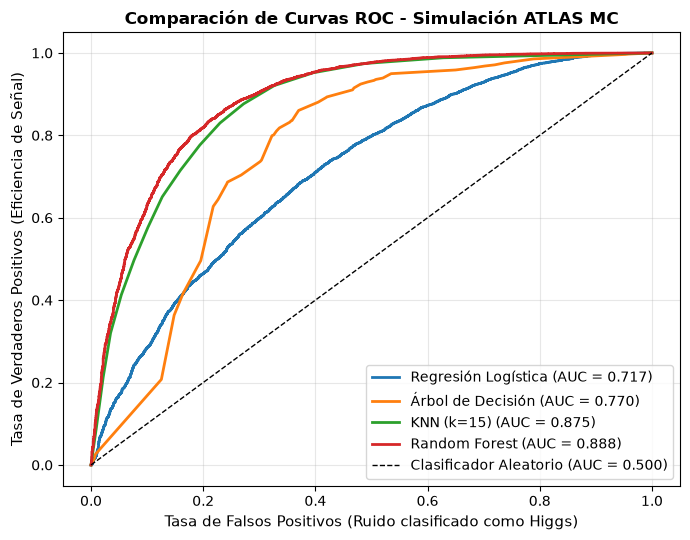

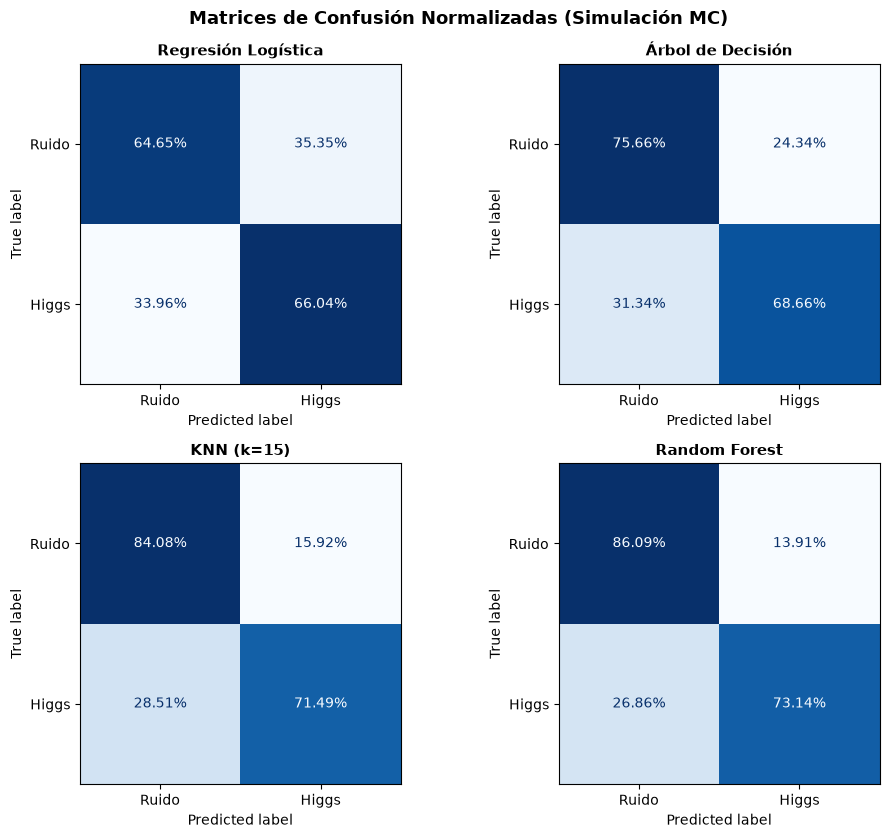

In [90]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

resultados_mc = []
factor_lumi = 1.0 / 0.30  # Escalar el 30% de test a la luminosidad total de 36.6 fb^-1

fig_roc, ax_roc = plt.subplots(figsize=(7, 5.5))
fig_cm, axes_cm = plt.subplots(2, 2, figsize=(10, 8.5))
axes_cm = axes_cm.ravel()

for idx, (nombre, modelo) in enumerate(modelos.items()):
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    # Métricas estándar
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    # Eventos esperados en 36.6 fb^-1 que el modelo clasifica como Higgs (pred == 1)
    esp_higgs_real = w_test[(y_test == 1) & (y_pred == 1)].sum() * factor_lumi
    esp_ruido_falso = w_test[(y_test == 0) & (y_pred == 1)].sum() * factor_lumi

    resultados_mc.append({
        "Modelo": nombre,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall (Sensibilidad)": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4),
        "Higgs Esperados (TP)": round(esp_higgs_real, 2),
        "Ruido Esperado (FP)": round(esp_ruido_falso, 2)
    })

    # Curva ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax_roc.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc:.3f})")

    # Matriz de confusión normalizada
    cm = confusion_matrix(y_test, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ruido", "Higgs"])
    disp.plot(ax=axes_cm[idx], cmap="Blues", colorbar=False, values_format=".2%")
    axes_cm[idx].set_title(nombre, fontsize=11, fontweight='bold')

# Tabla comparativa en consola
df_resultados_mc = pd.DataFrame(resultados_mc)
print("\nRESULTADOS EN SIMULACIÓN MONTE CARLO")
print(df_resultados_mc.to_string(index=False))

# Guardar gráfica de Curvas ROC
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='Clasificador Aleatorio (AUC = 0.500)')
ax_roc.set_xlabel('Tasa de Falsos Positivos (Ruido clasificado como Higgs)', fontsize=11)
ax_roc.set_ylabel('Tasa de Verdaderos Positivos (Eficiencia de Señal)', fontsize=11)
ax_roc.set_title('Comparación de Curvas ROC - Simulación ATLAS MC', fontsize=12, fontweight='bold')
ax_roc.legend(loc='lower right', frameon=True)
ax_roc.grid(alpha=0.3)
fig_roc.tight_layout()
fig_roc.savefig("images/Proyecto_integrador_graficas/curvas_roc_mc.png", dpi=300)

# Guardar gráfica de Matrices de Confusión
fig_cm.suptitle("Matrices de Confusión Normalizadas (Simulación MC)", fontsize=13, fontweight='bold')
fig_cm.tight_layout()
fig_cm.savefig("images/Proyecto_integrador_graficas/matrices_confusion_mc.png", dpi=300)
plt.show()

# Conteo real de cuántos eventos del detector ATLAS clasifica cada modelo como Bosón de Higgs y la distribución de masa $m_{4\ell}$ mostrando la acumulación alrededor de $125\text{ GeV}$.


CLASIFICACIÓN SOBRE DATOS REALES DE ATLAS (L = 36.6 fb^-1)
             Modelo  Total Eventos ATLAS  Clasificados Higgs (Señal)  Clasificados Ruido (Fondo)  Eventos en Pico (115-135 GeV)  Prob. Media Señal
Regresión Logística                 1075                         271                         804                             16              0.698
  Árbol de Decisión                 1075                         182                         893                             18              0.791
         KNN (k=15)                 1075                         113                         962                             19              0.683
      Random Forest                 1075                         112                         963                             15              0.603


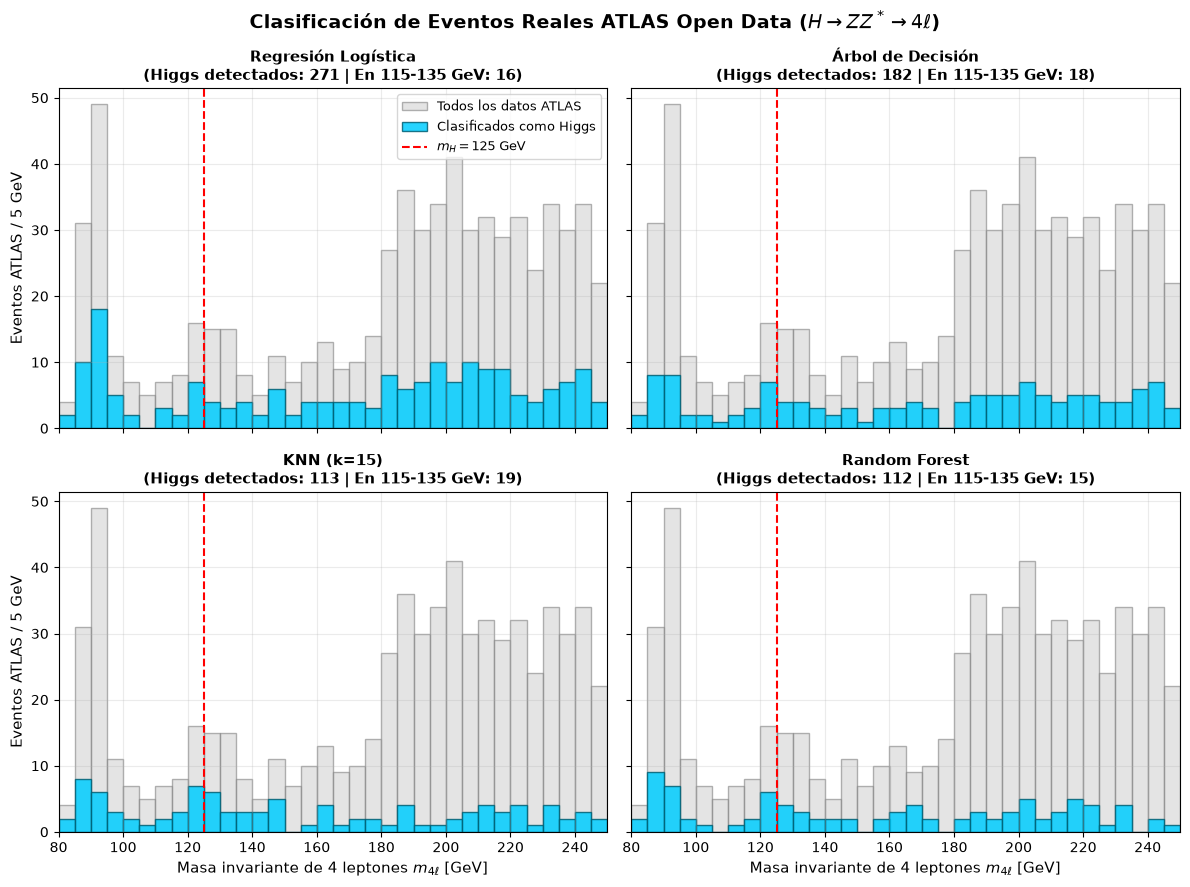

In [91]:
X_atlas = df_atlas_real[features]
resultados_atlas = []

fig_atlas, axes_atlas = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
axes_atlas = axes_atlas.ravel()

bins_masa = np.arange(80, 252.5, 5) # Bins de 5 GeV entre 80 y 250 GeV

for idx, (nombre, modelo) in enumerate(modelos.items()):
    pred_atlas = modelo.predict(X_atlas)
    prob_atlas = modelo.predict_proba(X_atlas)[:, 1]

    n_higgs_atlas = np.sum(pred_atlas == 1)
    n_ruido_atlas = np.sum(pred_atlas == 0)

    # Eventos en la ventana de masa del Higgs (115 - 135 GeV)
    masas_clasificadas_higgs = df_atlas_real.loc[pred_atlas == 1, 'mass']
    en_pico_125 = np.sum((masas_clasificadas_higgs >= 115) & (masas_clasificadas_higgs <= 135))

    resultados_atlas.append({
        "Modelo": nombre,
        "Total Eventos ATLAS": len(X_atlas),
        "Clasificados Higgs (Señal)": n_higgs_atlas,
        "Clasificados Ruido (Fondo)": n_ruido_atlas,
        "Eventos en Pico (115-135 GeV)": en_pico_125,
        "Prob. Media Señal": round(prob_atlas[pred_atlas == 1].mean(), 3) if n_higgs_atlas > 0 else 0
    })

    # Graficar histograma de masa invariante de los datos reales clasificados por el modelo
    ax = axes_atlas[idx]
    ax.hist(df_atlas_real['mass'], bins=bins_masa, color='#d3d3d3', edgecolor='gray', alpha=0.6, label='Todos los datos ATLAS')
    ax.hist(masas_clasificadas_higgs, bins=bins_masa, color='#00cdff', edgecolor='#005f73', alpha=0.85, label='Clasificados como Higgs')
    ax.axvline(125, color='red', linestyle='--', lw=1.5, label='$m_H = 125$ GeV')

    ax.set_title(f"{nombre}\n(Higgs detectados: {n_higgs_atlas} | En 115-135 GeV: {en_pico_125})", fontsize=11, fontweight='bold')
    ax.set_xlim(80, 250)
    ax.grid(alpha=0.25)
    if idx in [2, 3]:
        ax.set_xlabel(r'Masa invariante de 4 leptones $m_{4\ell}$ [GeV]', fontsize=11)
    if idx in [0, 2]:
        ax.set_ylabel('Eventos ATLAS / 5 GeV', fontsize=11)
    if idx == 0:
        ax.legend(loc='upper right', fontsize=9)

df_resultados_atlas = pd.DataFrame(resultados_atlas)
print("\nCLASIFICACIÓN SOBRE DATOS REALES DE ATLAS (L = 36.6 fb^-1)")
print(df_resultados_atlas.to_string(index=False))

fig_atlas.suptitle("Clasificación de Eventos Reales ATLAS Open Data ($H \\rightarrow ZZ^* \\rightarrow 4\\ell$)", fontsize=14, fontweight='bold')
fig_atlas.tight_layout()
fig_atlas.savefig("images/Proyecto_integrador_graficas/clasificacion_datos_atlas.png", dpi=300)
plt.show()

# Análisis de complejidad computacional ($\mathcal{O}$), tiempos de entrenamiento y tiempos de inferencia de los cuatro clasificadores supervisados.

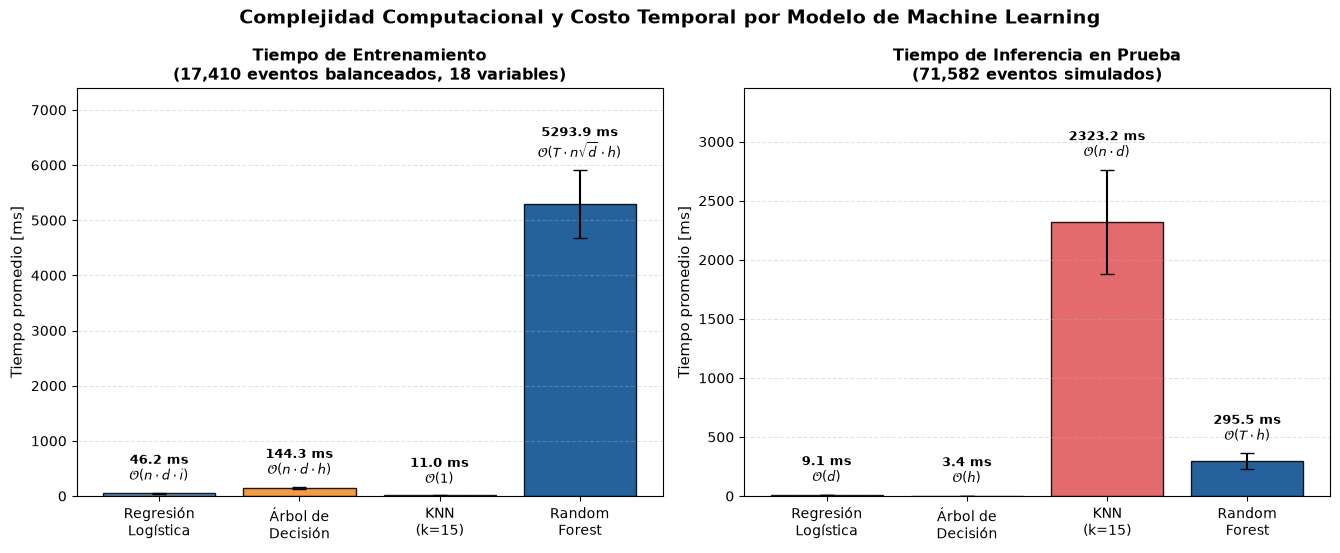

In [92]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

complejidad_teorica = {
    "Regresión Logística": {
        "train_O": r"$\mathcal{O}(n \cdot d \cdot i)$",
        "pred_O":  r"$\mathcal{O}(d)$",
    },
    "Árbol de Decisión": {
        "train_O": r"$\mathcal{O}(n \cdot d \cdot h)$",
        "pred_O":  r"$\mathcal{O}(h)$",
    },
    "KNN (k=15)": {
        "train_O": r"$\mathcal{O}(1)$",
        "pred_O":  r"$\mathcal{O}(n \cdot d)$",
    },
    "Random Forest": {
        "train_O": r"$\mathcal{O}(T \cdot n \sqrt{d} \cdot h)$",
        "pred_O":  r"$\mathcal{O}(T \cdot h)$",
    }
}

# 2. Medir tiempos de entrenamiento e inferencia (promedio de 5 ejecuciones)
n_repeticiones = 5
resultados_complejidad = []

for nombre, modelo_base in modelos.items():
    tiempos_train = []
    tiempos_pred = []

    for _ in range(n_repeticiones):
        clf = clone(modelo_base)

        t0 = time.perf_counter()
        clf.fit(X_train_bal, y_train_bal)
        t1 = time.perf_counter()
        tiempos_train.append((t1 - t0) * 1000.0)

        t2 = time.perf_counter()
        _ = clf.predict_proba(X_test)
        t3 = time.perf_counter()
        tiempos_pred.append((t3 - t2) * 1000.0)

    resultados_complejidad.append({
        "Modelo": nombre,
        "Complejidad Entrenamiento": complejidad_teorica[nombre]["train_O"],
        "Complejidad Inferencia (1 evento)": complejidad_teorica[nombre]["pred_O"],
        "Entrenamiento (ms)": round(np.mean(tiempos_train), 2),
        "Desv. Train (ms)": round(np.std(tiempos_train), 2),
        "Inferencia Test (ms)": round(np.mean(tiempos_pred), 2),
        "Desv. Inf. (ms)": round(np.std(tiempos_pred), 2)
    })

df_complejidad = pd.DataFrame(resultados_complejidad)

# comparación de tiempos
fig_comp, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6))
colores = ["#4e79a7", "#f28e2b", "#e15759", "#074c8f"]
etiquetas_x = ["Regresión\nLogística", "Árbol de\nDecisión", "KNN\n(k=15)", "Random\nForest"]

# Tiempo de Entrenamiento
y_train = df_complejidad["Entrenamiento (ms)"]
err_train = df_complejidad["Desv. Train (ms)"]
top_train = (y_train + err_train).max()

bars1 = ax1.bar(
    etiquetas_x, y_train, yerr=err_train,
    capsize=5, color=colores, edgecolor="black", alpha=0.88
)
ax1.set_title("Tiempo de Entrenamiento\n(17,410 eventos balanceados, 18 variables)", fontsize=11.5, fontweight="bold")
ax1.set_ylabel("Tiempo promedio [ms]", fontsize=11)
ax1.set_ylim(0, top_train * 1.25)
ax1.grid(axis="y", linestyle="--", alpha=0.35)

for bar, (_, row) in zip(bars1, df_complejidad.iterrows()):
    altura = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2.0,
        altura + row["Desv. Train (ms)"] + (top_train * 0.025),
        f"{altura:.1f} ms\n{row['Complejidad Entrenamiento']}",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

# Tiempo de Inferencia
y_inf = df_complejidad["Inferencia Test (ms)"]
err_inf = df_complejidad["Desv. Inf. (ms)"]
top_inf = (y_inf + err_inf).max()

bars2 = ax2.bar(
    etiquetas_x, y_inf, yerr=err_inf,
    capsize=5, color=colores, edgecolor="black", alpha=0.88
)
ax2.set_title("Tiempo de Inferencia en Prueba\n(71,582 eventos simulados)", fontsize=11.5, fontweight="bold")
ax2.set_ylabel("Tiempo promedio [ms]", fontsize=11)
ax2.set_ylim(0, top_inf * 1.25)
ax2.grid(axis="y", linestyle="--", alpha=0.35)

for bar, (_, row) in zip(bars2, df_complejidad.iterrows()):
    altura = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2.0,
        altura + row["Desv. Inf. (ms)"] + (top_inf * 0.025),
        f"{altura:.1f} ms\n{row['Complejidad Inferencia (1 evento)']}",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold"
    )

fig_comp.suptitle("Complejidad Computacional y Costo Temporal por Modelo de Machine Learning", fontsize=13.5, fontweight="bold")
fig_comp.tight_layout()
fig_comp.savefig("images/Proyecto_integrador_graficas/complejidad_computacional.png", dpi=300)
plt.show()

# comportamiento asintotico

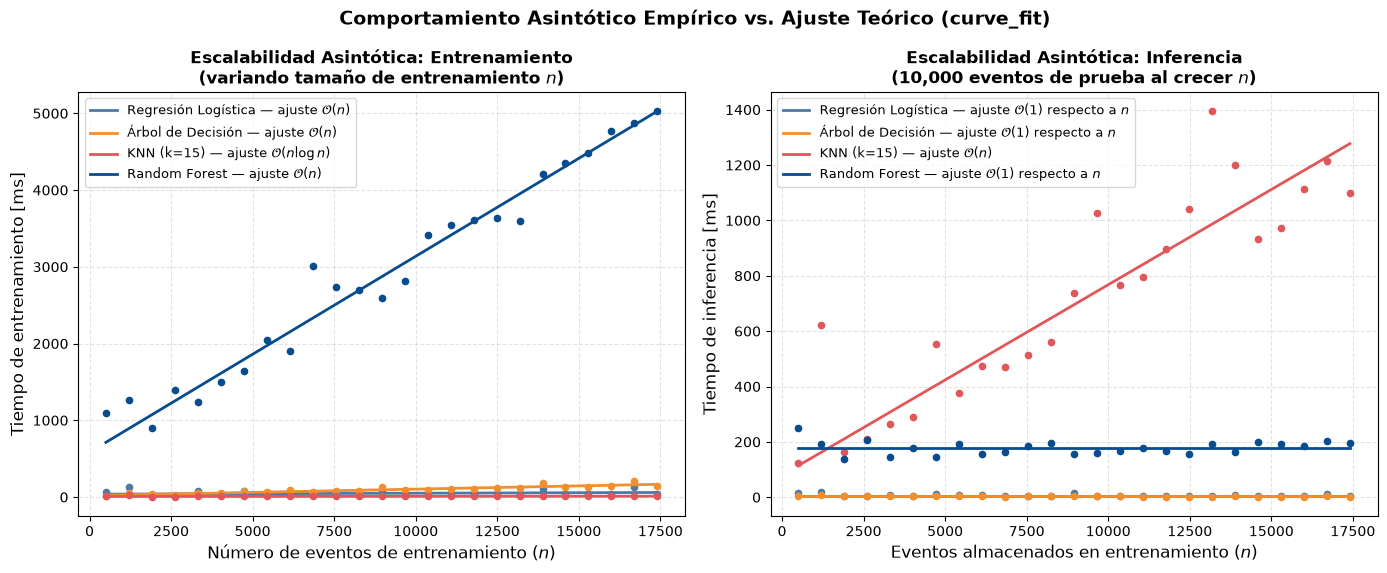

In [93]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from scipy.optimize import curve_fit

# Definir los tamaños de muestra n (desde 500 hasta los 17,410 eventos balanceados)
n_max = len(X_train_bal)
n_array_size = np.linspace(500, n_max, 25, dtype=int)

# Definir las funciones teóricas de complejidad en función de n (con d=18, h, T fijos)
def f_lineal(n, a, b):
    # O(n) -> Regresión Logística, Árbol de Decisión (h fijo) y Random Forest (T, h fijos)
    return a * n + b

def f_constante(n, a):
    # O(1) -> Almacenamiento en entrenamiento de KNN (brute-force / kd-tree ligero)
    return np.full_like(n, a, dtype=float)

def f_nlogn(n, a, b):
    # O(n log n) -> Construcción de árbol espacial (KD-Tree / Ball-Tree) en KNN
    return a * n * np.log2(n) + b

# Medir tiempos reales de entrenamiento e inferencia al variar n
tiempos_train = {nombre: [] for nombre in modelos}
tiempos_pred  = {nombre: [] for nombre in modelos}

# Subconjunto fijo de prueba (10,000 eventos) para evaluar cómo escala la inferencia con n
X_test_sub = X_test.iloc[:10000]

for n in n_array_size:
    X_sub = X_train_bal.iloc[:n]
    y_sub = y_train_bal.iloc[:n]

    for nombre, modelo_base in modelos.items():
        # Promedio de 3 corridas por punto para suavizar ruido del sistema operativo
        t_tr_runs, t_pr_runs = [], []
        for _ in range(3):
            clf = clone(modelo_base)

            t0 = time.perf_counter()
            clf.fit(X_sub, y_sub)
            t1 = time.perf_counter()
            t_tr_runs.append((t1 - t0) * 1000.0)

            t2 = time.perf_counter()
            _ = clf.predict_proba(X_test_sub)
            t3 = time.perf_counter()
            t_pr_runs.append((t3 - t2) * 1000.0)

        tiempos_train[nombre].append(np.mean(t_tr_runs))
        tiempos_pred[nombre].append(np.mean(t_pr_runs))

# Convertir listas a arreglos de NumPy
for nombre in modelos:
    tiempos_train[nombre] = np.array(tiempos_train[nombre])
    tiempos_pred[nombre]  = np.array(tiempos_pred[nombre])

# Graficar puntos experimentales y ajustes asintóticos con curve_fit
fig_asymp, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.8))
colores = {
    "Regresión Logística": "#4e79a7",
    "Árbol de Decisión":   "#f28e2b",
    "KNN (k=15)":          "#e15759",
    "Random Forest":       "#074c8f"
}

etiquetas_fit_train = {
    "Regresión Logística": (f_lineal, r"$\mathcal{O}(n)$"),
    "Árbol de Decisión":   (f_lineal, r"$\mathcal{O}(n)$"),
    "KNN (k=15)":          (f_nlogn,  r"$\mathcal{O}(n \log n)$"),
    "Random Forest":       (f_lineal, r"$\mathcal{O}(n)$")
}

etiquetas_fit_pred = {
    "Regresión Logística": (f_constante, r"$\mathcal{O}(1)$ respecto a $n$"),
    "Árbol de Decisión":   (f_constante, r"$\mathcal{O}(1)$ respecto a $n$"),
    "KNN (k=15)":          (f_lineal,    r"$\mathcal{O}(n)$"),
    "Random Forest":       (f_constante, r"$\mathcal{O}(1)$ respecto a $n$")
}

# Escalabilidad del Entrenamiento
for nombre in modelos:
    c = colores[nombre]
    func, label_o = etiquetas_fit_train[nombre]

    # Saltar los primeros 3 puntos (warm-up) para el ajuste asintótico
    popt, _ = curve_fit(func, n_array_size[3:], tiempos_train[nombre][3:])

    ax1.plot(n_array_size, tiempos_train[nombre], linestyle="", marker="o", markersize=4.5, color=c)
    ax1.plot(n_array_size, func(n_array_size, *popt), linestyle="-", lw=2, color=c,
             label=f"{nombre} — ajuste {label_o}")

ax1.set_title("Escalabilidad Asintótica: Entrenamiento\n(variando tamaño de entrenamiento $n$)", fontsize=12, fontweight="bold")
ax1.set_xlabel(r"Número de eventos de entrenamiento ($n$)", fontsize=12)
ax1.set_ylabel("Tiempo de entrenamiento [ms]", fontsize=12)
ax1.grid(True, linestyle="--", alpha=0.35)
ax1.legend(fontsize=9.5, loc="upper left", frameon=True)

# --- Subgráfica B: Escalabilidad de la Inferencia ---
for nombre in modelos:
    c = colores[nombre]
    func, label_o = etiquetas_fit_pred[nombre]

    popt, _ = curve_fit(func, n_array_size[3:], tiempos_pred[nombre][3:])

    ax2.plot(n_array_size, tiempos_pred[nombre], linestyle="", marker="o", markersize=4.5, color=c)
    ax2.plot(n_array_size, func(n_array_size, *popt), linestyle="-", lw=2, color=c,
             label=f"{nombre} — ajuste {label_o}")

ax2.set_title("Escalabilidad Asintótica: Inferencia\n(10,000 eventos de prueba al crecer $n$)", fontsize=12, fontweight="bold")
ax2.set_xlabel(r"Eventos almacenados en entrenamiento ($n$)", fontsize=12)
ax2.set_ylabel("Tiempo de inferencia [ms]", fontsize=12)
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.legend(fontsize=9.5, loc="upper left", frameon=True)

fig_asymp.suptitle("Comportamiento Asintótico Empírico vs. Ajuste Teórico (curve_fit)", fontsize=13.5, fontweight="bold")
fig_asymp.tight_layout()
fig_asymp.savefig("images/Proyecto_integrador_graficas/comportamiento_asintotico.png", dpi=300)
plt.show()

<img src="https://github.com/atlas-outreach-data-tools/notebooks-collection-opendata/blob/master/13-TeV-examples/uproot_python/images/conclusion_meme.jpeg?raw=1" style="width:50%">

## Función KNN a mano

In [94]:
def estandarizar_ajustar(X):  # calcula media y desviación de cada variable igual que StandardScaler.fit
    X = np.asarray(X, dtype=np.float64)  # convertimos el dataframe a arreglo de numoy en float64
    media = X.mean(axis=0)  # media de cada columna con un vector de 18 valores
    desv = X.std(axis=0)  # desviación estándar poblacional
    desv[desv == 0] = 1.0  # si alguna variable es constante evitamos dividir entre cero
    return media, desv  # regresamos los parámetros para reutilizarlos en prueba

def estandarizar_aplicar(X, media, desv):  # aplica el calculo del valor z. z = (x - media) / desv
    return (np.asarray(X, dtype=np.float64) - media) / desv  # usa la media/desv de ENTRENAMIENTO para no filtrar info del test

def knn_fit(X, y):  # entrenar KNN, solo memorizar los datos
    media, desv = estandarizar_ajustar(X)  # parámetros de estandarización, su comportamiento asintótico es O(n·d)
    X_std = estandarizar_aplicar(X, media, desv)  # guardamos los eventos de entrenamiento ya estandarizados
    return {  # el modelo es un diccionario con todo lo que necesitamos para predecir
        "X": X_std,  # matriz n × d de entrenamiento estandarizada
        "y": np.asarray(y, dtype=np.int64),  # etiquetas 0 = ruido, 1 = Higgs !!
        "norma2": np.sum(X_std**2, axis=1),  # precalculamos ||x_j||² de cada evento de entrenamiento (se reutiliza siempre)
        "media": media,  # media para estandarizar nuevos eventos
        "desv": desv,  # desviación para estandarizar nuevos eventos
    }

def knn_distancias2(X_lote, modelo):  # distancias euclidianas al cuadrado entre un conjunto de prueba y TODO el entrenamiento
    norma2_lote = np.sum(X_lote**2, axis=1)[:, None]  # ||a||² de cada evento del conjunto
    producto = X_lote @ modelo["X"].T  # productos punto a·b en una sola multiplicación de matrices
    d2 = norma2_lote + modelo["norma2"][None, :] - 2.0 * producto  # identidad ||a−b||² = ||a||² + ||b||² − 2a·b
    return np.maximum(d2, 0.0)  # recortamos negativos diminutos causados por redondeo de punto flotante

def knn_predict_proba(modelo, X, k=15, tam_lote=1000):  # probabilidad de ser Higgs = fracción de los k vecinos que son Higgs
    X_std = estandarizar_aplicar(X, modelo["media"], modelo["desv"])  # estandarizamos el test con parámetros de train
    m = X_std.shape[0]  # número de eventos a clasificar
    prob_higgs = np.empty(m)  # arreglo donde guardaremos P(Higgs) de cada evento
    for ini in range(0, m, tam_lote):  # procesamos por conjuntos, ya que 71,582 × 17,410 de golpe serían ~10 GB de RAM...
        fin = min(ini + tam_lote, m)  # índice final del lote/conjunto
        d2 = knn_distancias2(X_std[ini:fin], modelo)  # matriz de distancias del lote contra los n de entrenamiento
        idx_vecinos = np.argpartition(d2, k - 1, axis=1)[:, :k]  # índices de los k más cercanos en O(n), sin ordenar todo (sort sería O(n log n))
        votos = modelo["y"][idx_vecinos]  # etiquetas de esos k vecinos (matriz m_lote × k de ceros y unos)
        prob_higgs[ini:fin] = votos.mean(axis=1)  # votación: proporción de vecinos que son Higgs
    return np.column_stack([1.0 - prob_higgs, prob_higgs])  # mismo formato que sklearn: columna 0 = ruido, columna 1 = Higgs

def knn_predict(modelo, X, k=15, tam_lote=1000):  # clase final por mayoría de votos
    return (knn_predict_proba(modelo, X, k, tam_lote)[:, 1] > 0.5).astype(int)  # con k = 15 (impar) nunca hay empate en binario

# --- Prueba rápida sobre tu split real ---
knn_manual = knn_fit(X_train_bal, y_train_bal)  # entrenamos (memorizamos) con los 17,410 eventos balanceados
y_pred_knn_manual = knn_predict(knn_manual, X_test, k=15)  # clasificamos los 71,582 eventos de prueba
print(f"KNN manual (k=15) -> accuracy en test: {np.mean(y_pred_knn_manual == np.asarray(y_test)):.4f}")  # verificación rápida

KNN manual (k=15) -> accuracy en test: 0.7408


## Función regresión logística con descenso del gradiente a mano

Regresión logística manual -> tasa de aprendizaje: 1.092, iteraciones: 599, accuracy en test: 0.6575


Text(0.5, 1.0, 'Convergencia de la Regresión Logística manual')

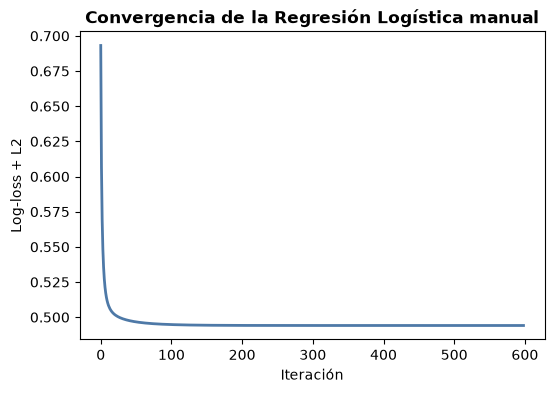

In [95]:
def sigmoide(z):  # función logística σ(z) = 1 / (1 + e^(−z)), convierte cualquier número en probabilidad entre 0 y 1
    z = np.clip(z, -500, 500)  # recortamos z para que np.exp no se desborde con valores enormes
    return 1.0 / (1.0 + np.exp(-z))  # fórmula de la sigmoide

def logreg_perdida(p, y, w, lam):  # log-loss (entropía cruzada binaria) + penalización L2
    eps = 1e-12  # pequeño valor para no calcular log(0)
    bce = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))  # entropía cruzada promedio
    return bce + 0.5 * lam * np.sum(w**2)  # sumamos la regularización L2, el sesgo b NO se regulariza, como en sklearn

def logreg_fit(X, y, tasa_aprendizaje=None, n_iter=3000, C=1.0, tol=1e-10):  # entrena por descenso de gradiente (None = tasa automática)
    media, desv = estandarizar_ajustar(X)  # misma estandarización que en KNN
    X_std = estandarizar_aplicar(X, media, desv)  # variables con media 0 y desviación 1
    y = np.asarray(y, dtype=np.float64)  # etiquetas como float para operar con probabilidades
    n, d = X_std.shape  # n eventos, d = 18 variables
    w = np.zeros(d)  # pesos iniciales en cero
    b = 0.0  # sesgo o intercepto inicial
    lam = 1.0 / (C * n)  # equivalencia con sklearn: minimizar 1/2||w||² + C·Σ loss  ⇔  mean(loss) + (1/(2Cn))·||w||²
    if tasa_aprendizaje is None:  # si no nos dan tasa, la calculamos para que el descenso sea estable
        Xb = np.column_stack([X_std, np.ones(n)])  # agregamos la columna de unos del sesgo
        L = 0.25 * np.linalg.eigvalsh(Xb.T @ Xb / n).max() + lam  # constante de Lipschitz del gradiente (σ' ≤ 1/4); matriz 19×19, cuesta O(n·d²)
        tasa_aprendizaje = 1.0 / L  # con paso 1/L el descenso de gradiente converge garantizado en problemas convexos
    historial = []  # guardamos la pérdida en cada iteración para graficar la convergencia
    for it in range(n_iter):  # cada iteración cuesta O(n·d), y en el entrenamiento total O(n·d·i)
        p = sigmoide(X_std @ w + b)  # predicción: probabilidad de Higgs para los n eventos
        error = p - y  # residuo (p − y); es la derivada de la log-loss respecto a z
        grad_w = X_std.T @ error / n + lam * w  # 3) gradiente de los pesos + término de regularización
        grad_b = error.mean()  # 3b) gradiente del sesgo
        w -= tasa_aprendizaje * grad_w  # 4) actualización: paso en dirección contraria al gradiente
        b -= tasa_aprendizaje * grad_b  # 4b) actualización del sesgo
        historial.append(logreg_perdida(p, y, w, lam))  # registramos la pérdida actual
        if it > 0 and abs(historial[-2] - historial[-1]) < tol:  # criterio de paro: la pérdida casi ya no cambia
            break  # convergió, salimos del ciclo
    return {"w": w, "b": b, "media": media, "desv": desv, "historial": np.array(historial),
            "n_iter": it + 1, "tasa": tasa_aprendizaje}  # modelo entrenado

def logreg_predict_proba(modelo, X):  # probabilidad de cada clase, cuesta O(d) por evento
    X_std = estandarizar_aplicar(X, modelo["media"], modelo["desv"])  # estandarizamos con parámetros de entrenamiento
    p = sigmoide(X_std @ modelo["w"] + modelo["b"])  # σ(w·x + b) = P(Higgs | x)
    return np.column_stack([1.0 - p, p])  # mismo formato que sklearn, P(ruido), P(Higgs)

def logreg_predict(modelo, X, umbral=0.5):  # clase final con umbral 0.5
    return (logreg_predict_proba(modelo, X)[:, 1] >= umbral).astype(int)  # 1 = Higgs si P ≥ 0.5

#entrenamiento y prueba rápida
logreg_manual = logreg_fit(X_train_bal, y_train_bal)  # entrenamos con el set balanceado
y_pred_lr_manual = logreg_predict(logreg_manual, X_test)  # clasificamos el set de prueba
print(f"Regresión logística manual -> tasa de aprendizaje: {logreg_manual['tasa']:.3f}, iteraciones: {logreg_manual['n_iter']}, "
      f"accuracy en test: {np.mean(y_pred_lr_manual == np.asarray(y_test)):.4f}")  # verificación rápida

# Curva de convergencia del descenso de gradiente
plt.figure(figsize=(6, 4))  # tamaño de la figura
plt.plot(logreg_manual["historial"], color="#4e79a7", lw=2)  # pérdida en cada iteración
plt.xlabel("Iteración")  # eje x
plt.ylabel("Log-loss + L2")  # eje y
plt.title("Convergencia de la Regresión Logística manual", fontweight="bold")  # título

## Medición de tiempos de las funciones hechas a mano con time_perf y comportamiento asintótico (O)

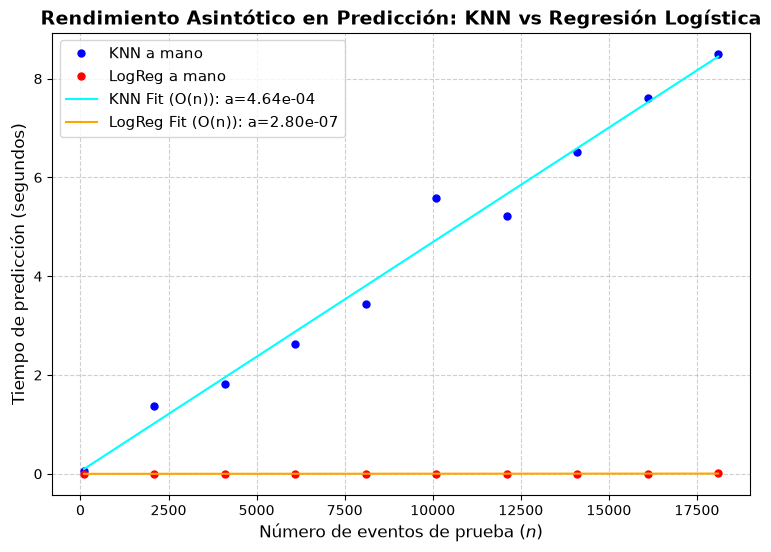

In [96]:
# 1. Definir la función de comportamiento asintótico (O(n) para predicción en ambos modelos)
def f_lineal(n, a, b):
    return a * n + b

# 2. Configurar los tamaños de n (subconjuntos de prueba)
n_array_size = np.arange(100, len(X_test), 2000)
times_knn = np.zeros(len(n_array_size), dtype=np.float64)
times_logreg = np.zeros(len(n_array_size), dtype=np.float64)

# 3. Medición de tiempos de ejecución
for idx, size in enumerate(n_array_size):
    X_subset = X_test[:size]  # Extraer subconjunto incremental de X_test

    # Tiempo de ejecución para KNN
    start_time = time.perf_counter()
    knn_predict(knn_manual, X_subset, k=15)
    times_knn[idx] = time.perf_counter() - start_time

    # Tiempo de ejecución para Regresión Logística
    start_time = time.perf_counter()
    logreg_predict(logreg_manual, X_subset)
    times_logreg[idx] = time.perf_counter() - start_time

# 4. Ajuste de curvas (Curve fitting) para modelar el crecimiento asintótico
popt_knn, _ = curve_fit(f_lineal, n_array_size, times_knn)
popt_logreg, _ = curve_fit(f_lineal, n_array_size, times_logreg)

# 5. Graficar los comportamientos
plt.figure(figsize=(9, 6))

# Puntos de datos medidos
plt.plot(n_array_size, times_knn, linestyle='', marker='o', markersize=5, color='blue', label='KNN a mano')
plt.plot(n_array_size, times_logreg, linestyle='', marker='o', markersize=5, color='red', label='LogReg a mano')

# Líneas de ajuste asintótico
plt.plot(n_array_size, f_lineal(n_array_size, *popt_knn), color='cyan', label=f'KNN Fit (O(n)): a={popt_knn[0]:.2e}')
plt.plot(n_array_size, f_lineal(n_array_size, *popt_logreg), color='orange', label=f'LogReg Fit (O(n)): a={popt_logreg[0]:.2e}')

plt.xlabel(r'Número de eventos de prueba ($n$)', fontsize=12)
plt.ylabel('Tiempo de predicción (segundos)', fontsize=12)
plt.title('Rendimiento Asintótico en Predicción: KNN vs Regresión Logística', fontweight='bold', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Comparación de los tiempos de las funciones a mano vs scikit-learn

### Complejidad Matemática de los Algoritmos a Mano:

Regresión Logística: La predicción tiene una complejidad de O(n * d), donde n es el número de eventos de prueba y d es la cantidad de variables (18). El cálculo consiste únicamente en un producto punto matricial (X_std @ w) y la aplicación de la función sigmoide. La gráfica mostrará una línea casi pegada al eje X, indicando una ejecución casi instantánea.

KNN: La predicción tiene una complejidad de O(n * N * d), donde N es el total de datos de entrenamiento (17,410), que se multiplica por cada evento de prueba n; el algoritmo calcula distancias euclidianas contra todos los eventos memorizados en entrenamiento. Aunque el crecimiento respecto a n sigue siendo lineal (O(n)), la pendiente de la curva de ajuste (a) será drásticamente mayor que la de la regresión logística.


### Comparación frente a Scikit-Learn:

Regresión Logística (Scikit-Learn): Muestra un comportamiento asintótico O(n * d) idéntico a tu función a mano. La diferencia en velocidad radica en que scikit-learn delega las operaciones matriciales a rutinas BLAS/LAPACK (mediante SciPy/NumPy) compiladas en C o Fortran, las cuales aprovechan la arquitectura del hardware para un procesamiento mucho más optimizado que las funciones de forma local hechas a mano.

KNN (Scikit-Learn): Con 18 variables, la configuración por defecto (algorithm='auto') utiliza fuerza bruta en lugar de estructuras espaciales como KD-Trees, compartiendo la misma complejidad asintótica nuestro código manual, que al ver que scikit learn usaba fuerza bruta, decidimos usar para nuestra función a mano ( O(n * N * d) ). La drástica reducción en el tiempo de predicción de scikit-learn no es por una mejora asintótica, sino porque escribe estas rutinas en Cython y C para evitar la sobrecarga de Python, implementando cálculo de distancias vectorizadas y paralelismo de bajo nivel (OpenMP) para usar múltiples hilos del procesador.